# 06 · Fine-tuning Polish RoBERTa-base-v2 na BAN-PL

Odtworzenie najlepszego modelu z publikacji **Kołos i in. (2024), *BAN-PL: a Polish Dataset of Banned Harmful and Offensive Content from Wykop.pl web service*** (arXiv:2308.10592, sek. 5.5, tab. 3).
W tab. 3 najlepszy wynik (F1 = 0.83 dla klasy szkodliwej) ma **Polish RoBERTa base v2** ([`sdadas/polish-roberta-base-v2`](https://huggingface.co/sdadas/polish-roberta-base-v2)), czyli model bazowy douczony na BAN-PL. Autorzy piszą też, że douczenie modelu bazowego działało lepiej niż douczanie modelu już nauczonego na innym zbiorze (HerBERT-HS, Polbert-CB).

| Model (tab. 3) | Recall | Precision | F1 |
|---|---|---|---|
| **RoBERTa base v2** | **0.84** | **0.83** | **0.83** |
| TrelBERT | 0.76 | 0.82 | 0.79 |
| Polbert-CB | 0.83 | 0.78 | 0.81 |
| HerBERT-HS | 0.79 | 0.80 | 0.79 |

**Hiperparametry**

| Parametr | Wartość | Źródło |
|---|---|---|
| model bazowy | `sdadas/polish-roberta-base-v2` | publikacja (tab. 3) |
| dane | BAN-PL, otwarta część (24 000 tekstów, 12 000 szkodliwych / 12 000 neutralnych) | publikacja |
| podział | 80% trening / 10% walidacja / 10% test (stratyfikowany, `SEED`) | publikacja |
| optymalizator | AdamW | publikacja |
| learning rate | 5e-5 | publikacja |
| early stopping | na **loss walidacyjnym**, patience = 5 epok, zostaje najlepszy checkpoint | publikacja |
| preprocessing | usunięcie `\n`, spacja po `USERNAME:` | publikacja |
| batch size, max długość, warmup, weight decay, max epok | 16, 256 tokenów, 6% kroków, 0.01, 20 | **nie podane w publikacji** – standardowe wartości dla RoBERTa-base |

**Jak model nie „zbiasować” na zbiór treningowy**
- Wybór modelu tylko na walidacji (early stopping na loss walidacyjnym, patience 5, przywrócenie najlepszych wag). Zbiór testowy jest użyty **raz**, na końcu.
- Krzywe uczenia (loss treningowy vs walidacyjny) – widać, od której epoki model zaczyna się przeuczać.
- `DEBIAS = True` usuwa artefakty BAN-PL, z których model nauczyłby się „na skróty” (szczegóły i liczby w kroku 1 oraz w `src/classifier/banpl.py`):
  - maska wulgaryzmów `#!$%@?` jest prawie tylko w klasie **neutralnej** (3,0% vs 0,008%), bo zbanowane teksty zapisano bez maski → model uczyłby się „maska = neutralne”; nasze komentarze mają inną maskę (`p------a`, 7% tekstów), której w BAN-PL nie ma. Obie maski są rozwijane słownikiem wulgaryzmów z repozytorium BAN-PL,
  - znaczniki anonimizacji (`{USERNAME}`, `{URL}`, `[surname]`, `#[pseudonym]`) różnią się częstością między klasami i nie występują w naszych danych → zamiana na format naszego pipeline'u i to samo czyszczenie (`src/preprocessing/cleaning.clean_text`), co nasze komentarze.
  - Z `DEBIAS = False` preprocessing jest dokładnie taki jak w publikacji.

**Wyjście**
```
models/polish-roberta-base-v2-banpl/      model + tokenizer (używa go notebook 07 i 08)
    training_meta.json                    hiperparametry, historia epok, wyniki na teście
    history.csv, split.csv                epoki; przydział tekstów BAN-PL do train/val/test
    polish_vulgarisms.txt                 słownik do rozwijania masek (ten sam przy predykcji)
models/_checkpoint/                       tylko w trakcie treningu (wznawianie po przerwaniu)
```
Trening można przerwać (Interrupt kernel) i odpalić komórkę ponownie – wznowi się od ostatniej pełnej epoki.
Szacowany czas: GPU ~2–4 min/epokę, Apple M (MPS) ~6–15 min/epokę, CPU kilka godzin. `SMOKE_TEST = True` – szybki test całego notebooka na 400 tekstach (model w `models/_smoke`).

In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
BASE_MODEL = "sdadas/polish-roberta-base-v2"
MODEL_DIRNAME = "polish-roberta-base-v2-banpl"   # models/<MODEL_DIRNAME>

BANPL_URL = "https://raw.githubusercontent.com/ZILiAT-NASK/BAN-PL/main/data/BAN-PL_1.zip"
BANPL_PASSWORD = b"BAN-PL_1"                     # hasło podane w repozytorium BAN-PL (data/README.md)
VULGARISMS_URL = ("https://raw.githubusercontent.com/ZILiAT-NASK/BAN-PL/main/resources/"
                  "polish_vulgarisms_extended_2.0.txt.")

# z publikacji
SPLIT = (0.8, 0.1, 0.1)       # train / val / test
LEARNING_RATE = 5e-5
PATIENCE = 5                  # epok bez poprawy loss walidacyjnego

# niepodane w publikacji
BATCH_SIZE = 16
MAX_LENGTH = 256              # tokeny; ~99% tekstów BAN-PL się mieści (patrz krok 3)
MAX_EPOCHS = 20               # górny limit – trening kończy early stopping
WARMUP_RATIO = 0.06
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0
SEED = 42

DEBIAS = True                 # False = preprocessing dokładnie jak w publikacji
SMOKE_TEST = False            # True = szybki test notebooka (400 tekstów, 1 epoka, models/_smoke)
FORCE = False                 # True = trenuj od nowa (kasuje checkpoint i zapisany model)
KEEP_CHECKPOINT = False       # True = zostaw models/_checkpoint po treningu (~1,5 GB)

In [2]:
# Jednorazowo, jeśli brakuje pakietów (odkomentuj):
# %pip install "torch>=2.6" transformers tqdm matplotlib

In [3]:
import io, json, os, random, shutil, sys, time, urllib.request, zipfile
from datetime import datetime
from pathlib import Path

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.classifier.banpl import PREPROCESSING_VERSION, Unmasker, model_input

BANPL_DIR = ROOT / "data" / "external" / "ban_pl"
MODELS = ROOT / "models"
OUT_MODEL = MODELS / ("_smoke" if SMOKE_TEST else MODEL_DIRNAME)
CKPT_DIR = MODELS / "_checkpoint"
if SMOKE_TEST:
    MAX_EPOCHS, CKPT_DIR = 1, MODELS / "_checkpoint_smoke"

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(os.cpu_count() or 4)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(SEED)
print(f"projekt : {ROOT}")
print(f"model   : {BASE_MODEL} -> {OUT_MODEL.relative_to(ROOT)}")
print(f"device  : {DEVICE}   | torch {torch.__version__}")

/Users/gosia/Desktop/SZT_SEM_2/AMC/AMC_FINAL/Social_Media_Hate_Speech/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/gosia/Desktop/SZT_SEM_2/AMC/AMC_FINAL/Social_Media_Hate_Speech/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


projekt : /Users/gosia/Desktop/SZT_SEM_2/AMC/AMC_FINAL/Social_Media_Hate_Speech
model   : sdadas/polish-roberta-base-v2 -> models/polish-roberta-base-v2-banpl
device  : mps   | torch 2.8.0


## 1. Dane BAN-PL i preprocessing

In [4]:
def _download(url, path):
    if not path.exists():
        print("pobieram", url)
        with urllib.request.urlopen(url, timeout=120) as r:
            data = r.read()
        tmp = path.with_suffix(path.suffix + ".tmp")
        tmp.write_bytes(data)
        os.replace(tmp, path)
    return path

def _ensure_gitignore(path, line):
    # dane i modele nie idą do gita (jak pozostałe dane w projekcie – DVC)
    lines = path.read_text(encoding="utf-8").splitlines() if path.exists() else []
    if line not in lines:
        path.write_text("\n".join(lines + [line]) + "\n", encoding="utf-8")

BANPL_DIR.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(exist_ok=True)
_ensure_gitignore(ROOT / "data" / "external" / ".gitignore", "/ban_pl")
_ensure_gitignore(MODELS / ".gitignore", "*")
_ensure_gitignore(MODELS / ".gitignore", "!.gitignore")

zip_p = _download(BANPL_URL, BANPL_DIR / "BAN-PL_1.zip")
vulg_p = _download(VULGARISMS_URL, BANPL_DIR / "polish_vulgarisms_extended_2.0.txt")
with zipfile.ZipFile(zip_p) as z:
    name = next(n for n in z.namelist() if n.endswith(".csv"))
    banpl = pd.read_csv(io.BytesIO(z.read(name, pwd=BANPL_PASSWORD)))
banpl = banpl.rename(columns={"Text": "text", "Class": "label"})[["id", "text", "label"]]
banpl["text"] = banpl["text"].fillna("").astype(str)
print(f"BAN-PL: {len(banpl):,} tekstów | {banpl['label'].value_counts().to_dict()}  (1 = szkodliwe)")

pobieram https://raw.githubusercontent.com/ZILiAT-NASK/BAN-PL/main/data/BAN-PL_1.zip
pobieram https://raw.githubusercontent.com/ZILiAT-NASK/BAN-PL/main/resources/polish_vulgarisms_extended_2.0.txt.
BAN-PL: 24,000 tekstów | {0: 12000, 1: 12000}  (1 = szkodliwe)


In [5]:
unmasker = Unmasker(vulg_p)
t0 = time.time()
banpl["x"] = [model_input(t, unmasker, from_banpl=True, debias=DEBIAS) for t in banpl["text"]]
print(f"preprocessing: {time.time() - t0:.1f}s | DEBIAS = {DEBIAS} | wersja {PREPROCESSING_VERSION}")

# artefakty, które różnią klasy: % tekstów w klasie neutralnej (0) i szkodliwej (1), przed i po
ARTEFACTS = {"{USERNAME}": "{USERNAME}", "{URL}": "{URL}", "[surname]/[pseudonym]": r"\[(?:surname|pseudonym)\]",
             "maska #!$%@?": r"#!\$%@\?", "maska p---a": r"(?<![\w-])\w-{2,}\w", "znak nowej linii": "\n",
             "cytat (>)": r"(?m)^\s*>", "lenny face / [lenny]": r"ʖ|\[lenny\]"}
rows = []
for k, pat in ARTEFACTS.items():
    regex = pat not in ("{USERNAME}", "{URL}")
    b = banpl["text"].str.contains(pat, regex=regex)
    a = banpl["x"].str.contains(pat, regex=regex)
    rows.append({"artefakt": k,
                 "przed: neutralne %": round(100 * b[banpl.label == 0].mean(), 2),
                 "przed: szkodliwe %": round(100 * b[banpl.label == 1].mean(), 2),
                 "po: neutralne %": round(100 * a[banpl.label == 0].mean(), 2),
                 "po: szkodliwe %": round(100 * a[banpl.label == 1].mean(), 2)})
display(pd.DataFrame(rows))

empty = banpl["x"].str.strip() == ""
print(f"puste po preprocessingu (np. sama wzmianka/link): {int(empty.sum())} -> usuwam")
banpl = banpl[~empty].reset_index(drop=True)

pd.set_option("display.max_colwidth", 160)
display(banpl[banpl["text"].str.contains(r"#!\$%@\?|\{USERNAME\}|\[surname\]")]
        .sample(6, random_state=SEED)[["label", "text", "x"]])

preprocessing: 1.6s | DEBIAS = True | wersja banpl-v1


,artefakt,przed: neutralne %,przed: szkodliwe %,po: neutralne %,po: szkodliwe %
0,{USERNAME},77.62,58.95,0.00,0.00
1,{URL},2.71,1.57,0.00,0.00
2,[surname]/[pseudonym],8.35,12.92,0.00,0.00
3,maska #!$%@?,3.03,0.01,0.00,0.00
4,maska p---a,0.00,0.00,0.00,0.00
5,znak nowej linii,45.12,31.81,0.00,0.00
6,cytat (>),7.92,5.42,0.00,0.00
7,lenny face / [lenny],9.48,7.23,9.33,7.07


puste po preprocessingu (np. sama wzmianka/link): 17 -> usuwam


,label,text,x
6883,0,{USERNAME}: Nie jest.,Nie jest.
19664,1,{USERNAME}: ok stuknięty młotku debilu,ok stuknięty młotku debilu
11494,0,"{USERNAME} w ogóle mnie dziwi to, że nie prowadziła takiej zagrożonej ciąży choćby w większym, bardziej cywilizowanym Krakowie z nieco lepszymi lekarzami ni...","w ogóle mnie dziwi to, że nie prowadziła takiej zagrożonej ciąży choćby w większym, bardziej cywilizowanym Krakowie z nieco lepszymi lekarzami niż w takiej ..."
21978,1,"{USERNAME}: Jebać innych, ważne że ja przeżyję nawet jak przejdę ciężko. Co z tego, że przy okazji jakaś babci pożegna się ze światem 5 lat wcześniej. Co z ...","Jebać innych, ważne że ja przeżyję nawet jak przejdę ciężko. Co z tego, że przy okazji jakaś babci pożegna się ze światem 5 lat wcześniej. Co z tego jak z k..."
23304,1,"{USERNAME}: nie bój, raz na gejowskiej stronie to nie pedał","nie bój, raz na gejowskiej stronie to nie pedał"
14271,1,"{USERNAME}: Widze neobolszewika z czasow PRLu w interpretacji prawa w Polin :) Potomek Borowskiego aka Bermana, kata Polakow? xD\nart. 8\n**Przepisy** Konst...","Widze neobolszewika z czasow PRLu w interpretacji prawa w Polin :) Potomek Borowskiego aka Bermana, kata Polakow? xD art. 8 **Przepisy** Konstytucji **stosu..."


## 2. Podział 80 / 10 / 10 (stratyfikowany)

In [6]:
rng = np.random.default_rng(SEED)
parts = []
for label, g in banpl.groupby("label"):
    idx = rng.permutation(g.index.values)
    n_tr, n_va = int(round(SPLIT[0] * len(idx))), int(round(SPLIT[1] * len(idx)))
    parts.append(pd.Series("train", index=idx[:n_tr]))
    parts.append(pd.Series("val", index=idx[n_tr:n_tr + n_va]))
    parts.append(pd.Series("test", index=idx[n_tr + n_va:]))
banpl["split"] = pd.concat(parts).sort_index()

if SMOKE_TEST:   # mały, zbalansowany wycinek
    keep = [g.sample(min(len(g), {"train": 100, "val": 25, "test": 25}[sp]), random_state=SEED)
            for (sp, _), g in banpl.groupby(["split", "label"])]
    banpl = pd.concat(keep).reset_index(drop=True)

display(banpl.groupby(["split", "label"]).size().unstack().assign(razem=lambda d: d.sum(axis=1)))
print("Publikacja: test = 2400 tekstów (1191 neutralnych, 1209 szkodliwych).")

label,0,1,razem
split,,,
test,1199,1199,2398
train,9590,9596,19186
val,1199,1200,2399


Publikacja: test = 2400 tekstów (1191 neutralnych, 1209 szkodliwych).


## 3. Model bazowy i tokenizacja

In [7]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
enc = tokenizer(banpl["x"].tolist(), truncation=False, add_special_tokens=True)["input_ids"]
n_tok = np.array([len(e) for e in enc])
print(f"tokeny: mediana {int(np.median(n_tok))}, p95 {int(np.percentile(n_tok, 95))}, p99 {int(np.percentile(n_tok, 99))}, "
      f"max {n_tok.max()} | > {MAX_LENGTH}: {(n_tok > MAX_LENGTH).mean():.2%} (przycinane)")

banpl["input_ids"] = tokenizer(banpl["x"].tolist(), truncation=True, max_length=MAX_LENGTH,
                               add_special_tokens=True)["input_ids"]
banpl["n_tokens"] = banpl["input_ids"].map(len)
data = {s: banpl[banpl["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}

def batches_for(df, shuffle, rng=None, bucket=50):
    # paczki podobnej długości (mniej paddingu = szybciej); w treningu kolejność losowa
    idx = rng.permutation(len(df)) if shuffle else np.arange(len(df))
    lens = df["n_tokens"].values
    out = []
    for k in range(0, len(idx), BATCH_SIZE * bucket):
        chunk = idx[k:k + BATCH_SIZE * bucket]
        chunk = chunk[np.argsort(lens[chunk], kind="stable")]
        out += [chunk[j:j + BATCH_SIZE] for j in range(0, len(chunk), BATCH_SIZE)]
    if shuffle:
        out = [out[i] for i in rng.permutation(len(out))]
    return out

def to_device(df, idx):
    enc = tokenizer.pad({"input_ids": df["input_ids"].iloc[idx].tolist()}, return_tensors="pt")
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    return enc, torch.tensor(df["label"].values[idx], device=DEVICE)

def new_model():
    m = AutoModelForSequenceClassification.from_pretrained(
        BASE_MODEL, num_labels=2, id2label={0: "neutral", 1: "harmful"}, label2id={"neutral": 0, "harmful": 1})
    return m.to(DEVICE)

tokeny: mediana 27, p95 133, p99 282, max 8678 | > 256: 1.23% (przycinane)


In [8]:
@torch.inference_mode()
def evaluate(model, df):
    model.eval()
    probs, loss_sum = np.empty(len(df), dtype=np.float32), 0.0
    for idx in batches_for(df, shuffle=False):
        enc, y = to_device(df, idx)
        logits = model(**enc).logits.float()
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        probs[idx] = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
    return loss_sum / len(df), probs

def metrics(y, prob, threshold=0.5):
    y, p = np.asarray(y).astype(int), (np.asarray(prob) >= threshold).astype(int)
    tp, fp = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum())
    fn, tn = int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec, "f1": f1,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}

## 4. Trening (early stopping na loss walidacyjnym)

Po każdej epoce: loss treningowy i walidacyjny, metryki walidacyjne dla klasy szkodliwej. Gdy loss walidacyjny się poprawia – zapis modelu do `models/polish-roberta-base-v2-banpl/`. Po `PATIENCE` epokach bez poprawy trening się kończy.
Checkpoint (`models/_checkpoint/last.pt`) zapisuje się po każdej epoce – po przerwaniu odpal komórkę jeszcze raz.

In [9]:
if FORCE:
    for d in (CKPT_DIR, OUT_MODEL):
        if d.exists():
            shutil.rmtree(d)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
ckpt_p = CKPT_DIR / "last.pt"
done_flag = OUT_MODEL / "training_meta.json"

if done_flag.exists() and json.loads(done_flag.read_text(encoding="utf-8")).get("finished"):
    print(f"Model już wytrenowany: {OUT_MODEL.relative_to(ROOT)} (FORCE = True, żeby trenować od nowa) – pomijam trening.")
else:
    model = new_model()
    no_decay = ("bias", "LayerNorm.weight", "layer_norm", "LayerNorm.bias")
    groups = [{"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)],
               "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],
               "weight_decay": 0.0}]
    optimizer = torch.optim.AdamW(groups, lr=LEARNING_RATE)
    steps_per_epoch = len(batches_for(data["train"], shuffle=False))
    total_steps = steps_per_epoch * MAX_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)

    state = {"epoch": 0, "history": [], "best_val_loss": float("inf"), "best_epoch": None, "bad_epochs": 0}
    if ckpt_p.exists():
        ck = torch.load(ckpt_p, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); state = ck["state"]
        print(f"wznawiam po epoce {state['epoch']} (najlepsza: {state['best_epoch']}, val loss {state['best_val_loss']:.4f})")

    t_start = time.time()
    try:
        while state["epoch"] < MAX_EPOCHS and state["bad_epochs"] < PATIENCE:
            epoch = state["epoch"] + 1
            rng = np.random.default_rng(SEED + epoch)
            model.train()
            tr_loss, n_seen, t0 = 0.0, 0, time.time()
            bar = tqdm(batches_for(data["train"], shuffle=True, rng=rng), desc=f"epoka {epoch}", unit="batch", leave=False)
            for idx in bar:
                enc, y = to_device(data["train"], idx)
                loss = F.cross_entropy(model(**enc).logits.float(), y)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
                tr_loss += loss.item() * len(idx); n_seen += len(idx)
                bar.set_postfix(loss=f"{tr_loss / n_seen:.4f}")
            bar.close()
            val_loss, val_prob = evaluate(model, data["val"])
            m = metrics(data["val"]["label"], val_prob)
            improved = val_loss < state["best_val_loss"]
            state["history"].append({"epoch": epoch, "train_loss": round(tr_loss / n_seen, 5), "val_loss": round(val_loss, 5),
                                     "val_precision": round(m["precision"], 4), "val_recall": round(m["recall"], 4),
                                     "val_f1": round(m["f1"], 4), "val_accuracy": round(m["accuracy"], 4),
                                     "lr": scheduler.get_last_lr()[0], "minutes": round((time.time() - t0) / 60, 1),
                                     "best": improved})
            if improved:
                state.update(best_val_loss=val_loss, best_epoch=epoch, bad_epochs=0)
                OUT_MODEL.mkdir(parents=True, exist_ok=True)
                model.save_pretrained(OUT_MODEL); tokenizer.save_pretrained(OUT_MODEL)
            else:
                state["bad_epochs"] += 1
            state["epoch"] = epoch
            tmp = ckpt_p.with_suffix(".tmp")
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                        "scheduler": scheduler.state_dict(), "state": state}, tmp)
            os.replace(tmp, ckpt_p)
            h = state["history"][-1]
            note = "← najlepsza, zapisano" if improved else "(bez poprawy {}/{})".format(state["bad_epochs"], PATIENCE)
            print(f"epoka {epoch:2d} | train loss {h['train_loss']:.4f} | val loss {h['val_loss']:.4f} | "
                  f"val P {h['val_precision']:.3f} R {h['val_recall']:.3f} F1 {h['val_f1']:.3f} | "
                  f"{h['minutes']} min {note}")
            if DEVICE.type == "mps":
                torch.mps.empty_cache()
    except KeyboardInterrupt:
        print(f"⏸ Przerwano. Ostatnia pełna epoka: {state['epoch']} – odpal komórkę ponownie, żeby wznowić.")
        raise
    stop = "early stopping" if state["bad_epochs"] >= PATIENCE else "limit MAX_EPOCHS"
    print(f"\nKoniec ({stop}) po {state['epoch']} epokach, {(time.time() - t_start) / 60:.1f} min w tej sesji. "
          f"Najlepsza epoka: {state['best_epoch']} (val loss {state['best_val_loss']:.4f}).")
    TRAIN_STATE = state

epoka  1 | train loss 0.3685 | val loss 0.3582 | val P 0.817 R 0.954 F1 0.880 | 2.7 min ← najlepsza, zapisano


epoka  2 | train loss 0.2971 | val loss 0.3184 | val P 0.951 R 0.787 F1 0.861 | 2.7 min ← najlepsza, zapisano


epoka  3 | train loss 0.2582 | val loss 0.3961 | val P 0.851 R 0.940 F1 0.893 | 2.8 min (bez poprawy 1/5)


epoka  4 | train loss 0.2322 | val loss 0.3254 | val P 0.929 R 0.878 F1 0.903 | 2.7 min (bez poprawy 2/5)


epoka  5 | train loss 0.2084 | val loss 0.3520 | val P 0.880 R 0.921 F1 0.900 | 2.8 min (bez poprawy 3/5)


epoka  6 | train loss 0.1899 | val loss 0.3386 | val P 0.913 R 0.896 F1 0.904 | 2.7 min (bez poprawy 4/5)


epoka  7 | train loss 0.1852 | val loss 0.3256 | val P 0.905 R 0.892 F1 0.899 | 2.7 min (bez poprawy 5/5)

Koniec (early stopping) po 7 epokach, 19.2 min w tej sesji. Najlepsza epoka: 2 (val loss 0.3183).


## 5. Krzywe uczenia – czy model się przeucza?

,epoch,train_loss,val_loss,val_precision,val_recall,val_f1,val_accuracy,lr,minutes,best
0,1,0.36852,0.35824,0.8167,0.9542,0.8801,0.8699,0.000042,2.7,True
1,2,0.29714,0.31835,0.9507,0.7875,0.8614,0.8733,0.000048,2.7,True
2,3,0.25817,0.39611,0.8513,0.9400,0.8935,0.8879,0.000045,2.8,False
3,4,0.23219,0.32544,0.9286,0.8783,0.9028,0.9054,0.000043,2.7,False
4,5,0.20843,0.35199,0.8805,0.9208,0.9002,0.8979,0.000040,2.8,False
5,6,0.18986,0.33857,0.9133,0.8958,0.9045,0.9054,0.000037,2.7,False
6,7,0.18521,0.32565,0.9053,0.8925,0.8989,0.8995,0.000035,2.7,False


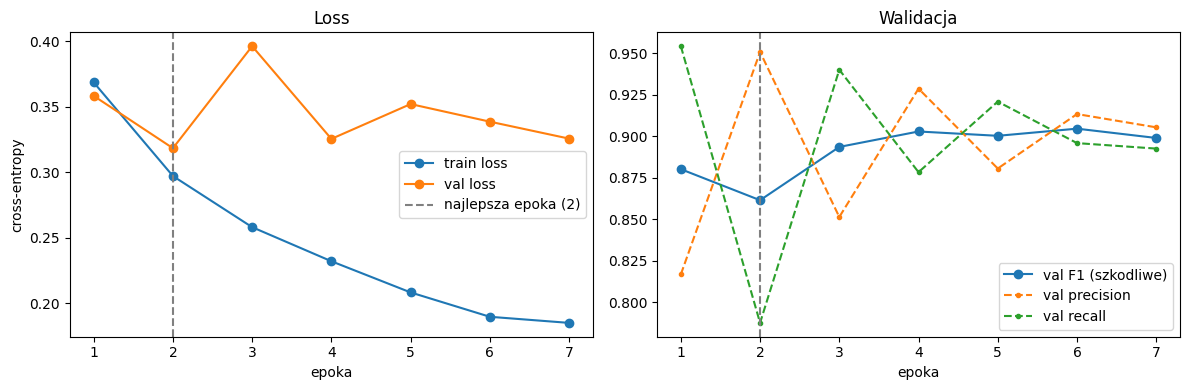

Najlepsza epoka 2: train loss 0.2971, val loss 0.3184 (różnica +0.0212). Epoki po niej (rosnący val loss przy spadającym train loss) to przeuczenie – ich wagi NIE są używane.


In [10]:
import matplotlib.pyplot as plt

if "TRAIN_STATE" in globals():
    history = pd.DataFrame(TRAIN_STATE["history"])
    history.to_csv(OUT_MODEL / "history.csv", index=False)
else:
    history = pd.read_csv(OUT_MODEL / "history.csv")
display(history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["epoch"], history["train_loss"], "o-", label="train loss")
ax[0].plot(history["epoch"], history["val_loss"], "o-", label="val loss")
best = int(history.loc[history["val_loss"].idxmin(), "epoch"])
ax[0].axvline(best, color="gray", ls="--", label=f"najlepsza epoka ({best})")
ax[0].set_xlabel("epoka"); ax[0].set_ylabel("cross-entropy"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(history["epoch"], history["val_f1"], "o-", label="val F1 (szkodliwe)")
ax[1].plot(history["epoch"], history["val_precision"], ".--", label="val precision")
ax[1].plot(history["epoch"], history["val_recall"], ".--", label="val recall")
ax[1].axvline(best, color="gray", ls="--")
ax[1].set_xlabel("epoka"); ax[1].legend(); ax[1].set_title("Walidacja")
plt.tight_layout(); plt.show()

b = history[history["epoch"] == best].iloc[0]
print(f"Najlepsza epoka {best}: train loss {b['train_loss']:.4f}, val loss {b['val_loss']:.4f} "
      f"(różnica {b['val_loss'] - b['train_loss']:+.4f}). Epoki po niej (rosnący val loss przy spadającym train loss) "
      "to przeuczenie – ich wagi NIE są używane.")

## 6. Test – raz, na najlepszym checkpoincie

In [11]:
best_model = AutoModelForSequenceClassification.from_pretrained(OUT_MODEL).to(DEVICE)
test_loss, test_prob = evaluate(best_model, data["test"])
m_test = metrics(data["test"]["label"], test_prob)

comparison = pd.DataFrame([
    {"model": "RoBERTa base v2 (publikacja, tab. 3)", "recall": 0.84, "precision": 0.83, "f1": 0.83, "accuracy": None},
    {"model": f"RoBERTa base v2 (ten notebook, DEBIAS={DEBIAS})", "recall": round(m_test["recall"], 3),
     "precision": round(m_test["precision"], 3), "f1": round(m_test["f1"], 3), "accuracy": round(m_test["accuracy"], 3)},
])
display(comparison)
cm = pd.DataFrame([[m_test["tn"], m_test["fp"]], [m_test["fn"], m_test["tp"]]],
                  index=["prawda: neutralne", "prawda: szkodliwe"], columns=["pred: neutralne", "pred: szkodliwe"])
display(cm)
print(f"test loss {test_loss:.4f} | n = {len(data['test'])}")

,model,recall,precision,f1,accuracy
0,"RoBERTa base v2 (publikacja, tab. 3)",0.840,0.830,0.830,NaN
1,"RoBERTa base v2 (ten notebook, DEBIAS=True)",0.779,0.932,0.849,0.861


,pred: neutralne,pred: szkodliwe
prawda: neutralne,1131,68
prawda: szkodliwe,265,934


test loss 0.3508 | n = 2398


In [12]:
# metadane + pliki potrzebne przy predykcji (notebook 07)
shutil.copyfile(vulg_p, OUT_MODEL / "polish_vulgarisms.txt")
banpl[["id", "label", "split"]].to_csv(OUT_MODEL / "split.csv", index=False)
hist = history.to_dict(orient="records")
meta = {
    "finished": True, "created_at": datetime.now().isoformat(timespec="seconds"),
    "base_model": BASE_MODEL, "dataset": "BAN-PL_1 (24 000, ZILiAT-NASK/BAN-PL)", "paper": "arXiv:2308.10592",
    "labels": {"0": "neutral", "1": "harmful"}, "hate_label_index": 1,
    "preprocessing": PREPROCESSING_VERSION, "debias": DEBIAS,
    "hyperparameters": {"optimizer": "AdamW", "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE,
                        "max_length": MAX_LENGTH, "max_epochs": MAX_EPOCHS, "early_stopping": "val_loss",
                        "patience": PATIENCE, "warmup_ratio": WARMUP_RATIO, "weight_decay": WEIGHT_DECAY,
                        "grad_clip": GRAD_CLIP, "split": SPLIT, "seed": SEED},
    "n": {s: int(len(d)) for s, d in data.items()},
    "best_epoch": int(best), "history": hist,
    "test": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_test.items()},
    "test_loss": round(test_loss, 5), "device": str(DEVICE), "smoke_test": SMOKE_TEST,
}
(OUT_MODEL / "training_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
if not KEEP_CHECKPOINT and CKPT_DIR.exists():
    shutil.rmtree(CKPT_DIR)
print("zapisano:", OUT_MODEL.relative_to(ROOT))
for p in sorted(OUT_MODEL.iterdir()):
    print(f"   {p.name:28s} {p.stat().st_size / 1e6:8.1f} MB")

zapisano: models/polish-roberta-base-v2-banpl
   config.json                       0.0 MB
   history.csv                       0.0 MB
   model.safetensors               497.8 MB
   polish_vulgarisms.txt             0.1 MB
   special_tokens_map.json           0.0 MB
   split.csv                         0.3 MB
   tokenizer.json                    3.4 MB
   tokenizer_config.json             0.0 MB
   training_meta.json                0.0 MB


In [13]:
# szybki sanity check (te same zdania co w notebookach 04/05)
SANITY = [
    "Dzień dobry, jutro ma padać deszcz.",
    "Bardzo ciekawy artykuł, dzięki za wrzutkę.",
    "Uchodźcy powinni dostać pomoc, to ludzie jak my.",
    "Wszystkich tych brudasów trzeba wywalić z kraju, to zwierzęta.",
    "Ty p--------y debilu, zdychaj.",
    "Imigranci to robactwo, które trzeba wytępić.",
]
s = pd.DataFrame({"text": SANITY, "label": 0})
s["input_ids"] = tokenizer([model_input(t, unmasker) for t in SANITY], truncation=True, max_length=MAX_LENGTH)["input_ids"]
s["n_tokens"] = s["input_ids"].map(len)
_, p = evaluate(best_model, s)
display(pd.DataFrame({"tekst": SANITY, "wejście modelu": [model_input(t, unmasker) for t in SANITY], "prob_harmful": p.round(3)}))
print("Dalej: notebook 07_roberta_banpl_hate.ipynb – predykcje na wydarzeniach (Wykop, Bluesky, YouTube).")

,tekst,wejście modelu,prob_harmful
0,"Dzień dobry, jutro ma padać deszcz.","Dzień dobry, jutro ma padać deszcz.",0.044
1,"Bardzo ciekawy artykuł, dzięki za wrzutkę.","Bardzo ciekawy artykuł, dzięki za wrzutkę.",0.048
2,"Uchodźcy powinni dostać pomoc, to ludzie jak my.","Uchodźcy powinni dostać pomoc, to ludzie jak my.",0.060
3,"Wszystkich tych brudasów trzeba wywalić z kraju, to zwierzęta.","Wszystkich tych brudasów trzeba wywalić z kraju, to zwierzęta.",0.947
4,"Ty p--------y debilu, zdychaj.","Ty pierdolacy debilu, zdychaj.",0.949
5,"Imigranci to robactwo, które trzeba wytępić.","Imigranci to robactwo, które trzeba wytępić.",0.947


Dalej: notebook 07_roberta_banpl_hate.ipynb – predykcje na wydarzeniach (Wykop, Bluesky, YouTube).
